# Olist E-commerce

> ข้อมูล: [Olist Brazilian E-Commerce](https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce) (CSV 8 ไฟล์ที่ใช้ในโน้ตบุ๊กนี้ ไม่ใช้ตารางรีวิว)

## 1) กำหนดปัญหา (Problem Definition)

**บริบท:** Olist เป็นตัวกลางที่เชื่อมร้านค้าขนาดเล็กเข้ากับ marketplace ในบราซิล เราสวมบทเป็นนักวิเคราะห์ข้อมูลที่ต้องช่วยผู้บริหารตัดสินใจ

**หัวข้อหลักและคำถามธุรกิจ**

| # | หัวข้อ | คำถามธุรกิจ | ตัวชี้วัด (KPI) |
|---|---|---|---|
| 1 | ยอดขาย | ยอดขายโตหรือชะลอ? หมวดสินค้าไหนสร้างรายได้หลัก และรายได้กระจุกตัวแค่ไหน? | ยอดขายรายเดือน, MoM growth, YoY, สัดส่วนรายได้ของ Top N หมวด (Pareto) |

**นิยามที่ใช้ตลอดโปรเจกต์**
- **ยอดขาย (revenue)** = ผลรวมของ `price` ใน order_items (ไม่รวมค่าส่ง `freight_value`)
- **ขอบเขตออเดอร์** = เฉพาะออเดอร์ที่ `order_status = 'delivered'` และมีวันที่ลูกค้าได้รับสินค้า (นับเฉพาะยอดขายที่ส่งสำเร็จจริง)
- **ลูกค้า** = `customer_unique_id` (ไม่ใช่ `customer_id` เพราะ Olist สร้าง `customer_id` ใหม่ทุกออเดอร์) เก็บไว้ในตารางสะอาดเพื่อใช้ต่อในอนาคต


## 2) เตรียมสภาพแวดล้อมและโหลดข้อมูล

โน้ตบุ๊กนี้ดาวน์โหลด CSV ทั้งหมดจาก Kaggle อัตโนมัติด้วย `kagglehub` (ดาวน์โหลดครั้งเดียวแล้วเก็บแคชในเครื่อง)

In [ ]:
!pip install -q kagglehub

In [ ]:
import kagglehub
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

# โหลดจาก Kaggle แล้วใช้โฟลเดอร์ที่ได้เป็น DATA_DIR
DATA_DIR = Path(kagglehub.dataset_download("olistbr/brazilian-ecommerce"))
print(DATA_DIR)

Using Colab cache for faster access to the 'brazilian-ecommerce' dataset.
/kaggle/input/brazilian-ecommerce


In [ ]:
FILES = {
    "customers":            "olist_customers_dataset.csv",
    "geolocation":          "olist_geolocation_dataset.csv",
    "order_items":          "olist_order_items_dataset.csv",
    "payments":             "olist_order_payments_dataset.csv",
    "orders":               "olist_orders_dataset.csv",
    "products":             "olist_products_dataset.csv",
    "sellers":              "olist_sellers_dataset.csv",
    "category_translation": "product_category_name_translation.csv",
}

# อ่านทุกไฟล์เข้า dict ชื่อ dfs เพื่อวนตรวจพร้อมกันทุกตารางได้
dfs = {name: pd.read_csv(DATA_DIR / fname) for name, fname in FILES.items()}
print("โหลดสำเร็จ", len(dfs), "ตาราง")

โหลดสำเร็จ 8 ตาราง


## 3) ภาพรวมของแต่ละตาราง



In [ ]:
overview = pd.DataFrame({
    "แถว":      {n: d.shape[0] for n, d in dfs.items()},
    "คอลัมน์":  {n: d.shape[1] for n, d in dfs.items()},
    "หน่วยความจำ (MB)": {n: d.memory_usage(deep=True).sum() / 1e6 for n, d in dfs.items()},
})
display(overview.sort_values("แถว", ascending=False))

,แถว,คอลัมน์,หน่วยความจำ (MB)
geolocation,1000163,5,135.67
order_items,112650,7,37.74
payments,103886,5,17.02
customers,99441,5,27.88
orders,99441,8,55.51
products,32951,9,6.60
sellers,3095,4,0.62
category_translation,71,2,0.01


In [ ]:
# ดูตัวอย่าง 3 แถวแรกของแต่ละตาราง
for name, d in dfs.items():
    print(f"\n=== {name} ===")
    display(d.head(3))


=== customers ===


,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP



=== geolocation ===


,geolocation_zip_code_prefix,geolocation_lat,geolocation_lng,geolocation_city,geolocation_state
0,1037,-23.55,-46.64,sao paulo,SP
1,1046,-23.55,-46.64,sao paulo,SP
2,1046,-23.55,-46.64,sao paulo,SP



=== order_items ===


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87


... (6 outputs left out)


=== sellers ===


,seller_id,seller_zip_code_prefix,seller_city,seller_state
0,3442f8959a84dea7ee197c632cb2df15,13023,campinas,SP
1,d1b65fc7debc3361ea86b5f14c68d2e2,13844,mogi guacu,SP
2,ce3ad9de960102d0677a81f5d0bb7b2d,20031,rio de janeiro,RJ



=== category_translation ===


,product_category_name,product_category_name_english
0,beleza_saude,health_beauty
1,informatica_acessorios,computers_accessories
2,automotivo,auto


## 4) ตรวจค่าว่าง (Missing Values)



In [ ]:
def missing_report(df):
    n = df.isna().sum()
    out = pd.DataFrame({"missing": n, "missing_%": n / len(df) * 100})
    return out[out["missing"] > 0].sort_values("missing", ascending=False)

for name, d in dfs.items():
    rep = missing_report(d)
    print(f"\n=== {name} ===")
    if rep.empty:
        print("ไม่มีค่าว่าง")
    else:
        display(rep)


=== customers ===
ไม่มีค่าว่าง

=== geolocation ===
ไม่มีค่าว่าง

=== order_items ===
ไม่มีค่าว่าง

=== payments ===
ไม่มีค่าว่าง

=== orders ===


,missing,missing_%
order_delivered_customer_date,2965,2.98
order_delivered_carrier_date,1783,1.79
order_approved_at,160,0.16



=== products ===


,missing,missing_%
product_category_name,610,1.85
product_name_lenght,610,1.85
product_description_lenght,610,1.85
product_photos_qty,610,1.85
product_weight_g,2,0.01
product_length_cm,2,0.01
product_height_cm,2,0.01
product_width_cm,2,0.01



=== sellers ===
ไม่มีค่าว่าง

=== category_translation ===
ไม่มีค่าว่าง


## 5) ตรวจค่าซ้ำ (Duplicates)

1. **ซ้ำทั้งแถว (full-row duplicates):** ทุกคอลัมน์เหมือนกันเป๊ะ
2. **ซ้ำที่ key (key duplicates):** คอลัมน์ที่ควรเป็นค่าเฉพาะ (primary key) กลับมีค่าซ้ำ ซึ่งจะทำให้ตอน JOIN แถวถูกคูณจนยอดขายเกินจริง


In [ ]:
KEYS = {
    "customers":            ["customer_id"],
    "orders":               ["order_id"],
    "order_items":          ["order_id", "order_item_id"],
    "payments":             ["order_id", "payment_sequential"],
    "products":             ["product_id"],
    "sellers":              ["seller_id"],
    "category_translation": ["product_category_name"],
    "geolocation":          None,   # ไม่มี primary key
}

rows = []
for name, d in dfs.items():
    key = KEYS[name]
    rows.append({
        "ตาราง": name,
        "แถวซ้ำทั้งแถว": int(d.duplicated().sum()),
        "key ที่ตรวจ": ", ".join(key) if key else "-",
        "แถวซ้ำที่ key": int(d.duplicated(subset=key).sum()) if key else np.nan,
    })
dup_report = pd.DataFrame(rows).set_index("ตาราง")
display(dup_report)

,แถวซ้ำทั้งแถว,key ที่ตรวจ,แถวซ้ำที่ key
ตาราง,,,
customers,0,customer_id,0.00
geolocation,261831,-,NaN
order_items,0,"order_id, order_item_id",0.00
payments,0,"order_id, payment_sequential",0.00
orders,0,order_id,0.00
products,0,product_id,0.00
sellers,0,seller_id,0.00
category_translation,0,product_category_name,0.00


In [ ]:
# เช็กเพิ่ม: customer_id vs customer_unique_id
c = dfs["customers"]
print("จำนวน customer_id ที่ไม่ซ้ำ       :", c["customer_id"].nunique())
print("จำนวน customer_unique_id ที่ไม่ซ้ำ:", c["customer_unique_id"].nunique())
print("-> ถ้า 2 ตัวเลขนี้ต่างกัน แปลว่ามีลูกค้าคนเดียวกันที่ซื้อหลายออเดอร์ (ต้องใช้ customer_unique_id นับลูกค้า)")

จำนวน customer_id ที่ไม่ซ้ำ       : 99441
จำนวน customer_unique_id ที่ไม่ซ้ำ: 96096
-> ถ้า 2 ตัวเลขนี้ต่างกัน แปลว่ามีลูกค้าคนเดียวกันที่ซื้อหลายออเดอร์ (ต้องใช้ customer_unique_id นับลูกค้า)


## 6) แปลงชนิดข้อมูล (Data Types)

คอลัมน์วันที่ถูกอ่านเข้ามาเป็นข้อความ (`object`) ต้องแปลงเป็น `datetime` ก่อน จึงจะคำนวณส่วนต่างวัน และจัดกลุ่มรายเดือนได้

In [ ]:
orders = dfs["orders"].copy()
order_items = dfs["order_items"].copy()
payments = dfs["payments"].copy()
customers = dfs["customers"].copy()
products = dfs["products"].copy()
sellers = dfs["sellers"].copy()
translation = dfs["category_translation"].copy()

ORDER_DATE_COLS = [
    "order_purchase_timestamp", "order_approved_at",
    "order_delivered_carrier_date", "order_delivered_customer_date",
    "order_estimated_delivery_date",
]
for col in ORDER_DATE_COLS:
    orders[col] = pd.to_datetime(orders[col], errors="coerce")

order_items["shipping_limit_date"] = pd.to_datetime(order_items["shipping_limit_date"], errors="coerce")

print(orders[ORDER_DATE_COLS].dtypes)

order_purchase_timestamp         datetime64[ns]
order_approved_at                datetime64[ns]
order_delivered_carrier_date     datetime64[ns]
order_delivered_customer_date    datetime64[ns]
order_estimated_delivery_date    datetime64[ns]
dtype: object


## 7) ตรวจสถานะออเดอร์ และช่วงเวลาของข้อมูล

ก่อนวิเคราะห์ยอดขายต้องรู้ว่า (1) มีออเดอร์สถานะไหนบ้าง และ (2) ข้อมูลครอบคลุมช่วงเวลาไหน

In [ ]:
status = orders["order_status"].value_counts().to_frame("ออเดอร์")
status["%"] = status["ออเดอร์"] / status["ออเดอร์"].sum() * 100
display(status)

print("ช่วงเวลาที่สั่งซื้อ:",
      orders["order_purchase_timestamp"].min(), "ถึง", orders["order_purchase_timestamp"].max())

,ออเดอร์,%
order_status,,
delivered,96478,97.02
shipped,1107,1.11
canceled,625,0.63
unavailable,609,0.61
invoiced,314,0.32
processing,301,0.30
created,5,0.01
approved,2,0.00


ช่วงเวลาที่สั่งซื้อ: 2016-09-04 21:15:19 ถึง 2018-10-17 17:30:18


/tmp/ipykernel_573/4282687233.py:12: UserWarning: Glyph 3629 (\N{THAI CHARACTER O ANG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_573/4282687233.py:12: UserWarning: Glyph 3648 (\N{THAI CHARACTER SARA E}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_573/4282687233.py:12: UserWarning: Glyph 3604 (\N{THAI CHARACTER DO DEK}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_573/4282687233.py:12: UserWarning: Glyph 3619 (\N{THAI CHARACTER RO RUA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_573/4282687233.py:12: UserWarning: Glyph 3660 (\N{THAI CHARACTER THANTHAKHAT}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_573/4282687233.py:12: UserWarning: Glyph 3592 (\N{THAI CHARACTER CHO CHAN}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_573/4282687233.py:12: UserWarning: Glyph 3635 (\N{THAI CHARACTER SARA AM}) missing from font(s) DejaVu Sans.
  plt.

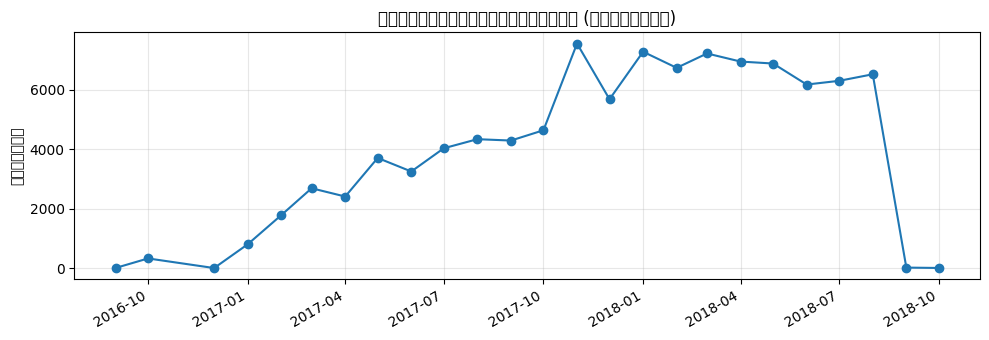

In [ ]:
# จำนวนออเดอร์รายเดือน (ดูว่าเดือนไหนข้อมูลบางผิดปกติ)
monthly = (orders
           .assign(month=orders["order_purchase_timestamp"].dt.to_period("M").dt.to_timestamp())
           .groupby("month").size())

fig, ax = plt.subplots(figsize=(10, 3.5))
monthly.plot(ax=ax, marker="o")
ax.set_title("Monthly number of orders (all statuses)")
ax.set_xlabel("")
ax.set_ylabel("Orders")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 8) ตรวจความสมเหตุสมผลของวันที่ (Logical Consistency)



In [ ]:
o = orders
checks = {
    "อนุมัติก่อนวันสั่งซื้อ":
        (o["order_approved_at"] < o["order_purchase_timestamp"]).sum(),
    "ส่งให้ขนส่งก่อนวันอนุมัติ":
        (o["order_delivered_carrier_date"] < o["order_approved_at"]).sum(),
    "ลูกค้าได้รับก่อนวันส่งให้ขนส่ง":
        (o["order_delivered_customer_date"] < o["order_delivered_carrier_date"]).sum(),
    "status = delivered แต่ไม่มีวันที่ลูกค้าได้รับ":
        ((o["order_status"] == "delivered") & o["order_delivered_customer_date"].isna()).sum(),
    "มีวันที่ลูกค้าได้รับ แต่ status ไม่ใช่ delivered":
        ((o["order_status"] != "delivered") & o["order_delivered_customer_date"].notna()).sum(),
}
logic = pd.DataFrame({"จำนวนแถวที่ผิดปกติ": checks})
logic["% ของออเดอร์ทั้งหมด"] = logic["จำนวนแถวที่ผิดปกติ"] / len(o) * 100
display(logic)

,จำนวนแถวที่ผิดปกติ,% ของออเดอร์ทั้งหมด
อนุมัติก่อนวันสั่งซื้อ,0,0.00
ส่งให้ขนส่งก่อนวันอนุมัติ,1359,1.37
ลูกค้าได้รับก่อนวันส่งให้ขนส่ง,23,0.02
status = delivered แต่ไม่มีวันที่ลูกค้าได้รับ,8,0.01
มีวันที่ลูกค้าได้รับ แต่ status ไม่ใช่ delivered,6,0.01


## 9) ตรวจความสัมพันธ์ระหว่างตาราง (Referential Integrity)



In [ ]:
def orphan_count(child, child_col, parent, parent_col):
    return int((~child[child_col].isin(parent[parent_col])).sum())

ri = pd.DataFrame([
    ("order_items.order_id   -> orders",      orphan_count(order_items, "order_id", orders, "order_id")),
    ("order_items.product_id -> products",    orphan_count(order_items, "product_id", products, "product_id")),
    ("order_items.seller_id  -> sellers",     orphan_count(order_items, "seller_id", sellers, "seller_id")),
    ("orders.customer_id     -> customers",   orphan_count(orders, "customer_id", customers, "customer_id")),
    ("payments.order_id      -> orders",      orphan_count(payments, "order_id", orders, "order_id")),
], columns=["ความสัมพันธ์ (ลูก -> แม่)", "orphan (หาแม่ไม่เจอ)"]).set_index("ความสัมพันธ์ (ลูก -> แม่)")
display(ri)

# ออเดอร์ที่ไม่มีรายการสินค้าเลย (มีใน orders แต่ไม่มีใน order_items)
no_items = orders[~orders["order_id"].isin(order_items["order_id"])]
print("\nออเดอร์ที่ไม่มีรายการสินค้า:", len(no_items))
display(no_items["order_status"].value_counts().to_frame("ออเดอร์"))

,orphan (หาแม่ไม่เจอ)
ความสัมพันธ์ (ลูก -> แม่),
order_items.order_id -> orders,0
order_items.product_id -> products,0
order_items.seller_id -> sellers,0
orders.customer_id -> customers,0
payments.order_id -> orders,0



ออเดอร์ที่ไม่มีรายการสินค้า: 775


,ออเดอร์
order_status,
unavailable,603
canceled,164
created,5
invoiced,2
shipped,1


## 10) ตรวจตาราง products และการแปลชื่อหมวดสินค้า

ชื่อหมวดสินค้าเป็นภาษาโปรตุเกส ต้องแปลเป็นอังกฤษผ่านตาราง `category_translation` ก่อนทำ dashboard ถ้าหมวดไหนไม่มีคำแปลหรือเป็นค่าว่าง จะกลายเป็นช่องว่างบนกราฟ

In [ ]:
cats_in_products = set(products["product_category_name"].dropna().unique())
cats_in_translation = set(translation["product_category_name"].unique())

no_translation = sorted(cats_in_products - cats_in_translation)
print("สินค้าที่ไม่มีชื่อหมวด (NaN):", int(products["product_category_name"].isna().sum()), "รายการ")
print("หมวดที่ไม่มีคำแปล:", no_translation if no_translation else "ไม่มี")

สินค้าที่ไม่มีชื่อหมวด (NaN): 610 รายการ
หมวดที่ไม่มีคำแปล: ['pc_gamer', 'portateis_cozinha_e_preparadores_de_alimentos']


In [ ]:
# ใช้ชื่อหมวดภาษาอังกฤษ ถ้าไม่มีให้ใส่ 'unknown'
products = products.merge(translation, on="product_category_name", how="left")
products["category_en"] = (products["product_category_name_english"]
                           .fillna(products["product_category_name"])
                           .fillna("unknown"))
print("จำนวนหมวดที่ไม่ซ้ำ:", products["category_en"].nunique())
display(products["category_en"].value_counts().head(10).to_frame("จำนวนสินค้า"))

จำนวนหมวดที่ไม่ซ้ำ: 74


,จำนวนสินค้า
category_en,
bed_bath_table,3029
sports_leisure,2867
furniture_decor,2657
health_beauty,2444
housewares,2335
auto,1900
computers_accessories,1639
toys,1411
watches_gifts,1329


## 11) ตรวจค่าผิดปกติ (Outliers) และค่าที่เป็นไปไม่ได้

ตรวจราคา ค่าส่ง และยอดชำระ โดยดู 3 อย่าง
1. **ค่าที่เป็นไปไม่ได้** เช่น ราคาติดลบ, ค่าส่งติดลบ
2. **ค่าศูนย์** ที่น่าสงสัย
3. **Outlier ทางสถิติ** ด้วยวิธี IQR (ค่าที่เกิน Q3 + 1.5 x IQR)

In [ ]:
display(order_items[["price", "freight_value"]].describe().T)

print("\nราคา <= 0       :", int((order_items["price"] <= 0).sum()))
print("ค่าส่งติดลบ      :", int((order_items["freight_value"] < 0).sum()))
print("ค่าส่ง = 0       :", int((order_items["freight_value"] == 0).sum()), "(อาจเป็นโปรส่งฟรี)")

,count,mean,std,min,25%,50%,75%,max
price,"112,650.00",120.65,183.63,0.85,39.90,74.99,134.90,"6,735.00"
freight_value,"112,650.00",19.99,15.81,0.00,13.08,16.26,21.15,409.68



ราคา <= 0       : 0
ค่าส่งติดลบ      : 0
ค่าส่ง = 0       : 383 (อาจเป็นโปรส่งฟรี)


price: เกินเกณฑ์ IQR 8,427 รายการ (7.5%) | เกณฑ์บน = 277.40
freight_value: เกินเกณฑ์ IQR 11,613 รายการ (10.3%) | เกณฑ์บน = 33.25


/tmp/ipykernel_573/2676017924.py:16: UserWarning: Glyph 3585 (\N{THAI CHARACTER KO KAI}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_573/2676017924.py:16: UserWarning: Glyph 3634 (\N{THAI CHARACTER SARA AA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_573/2676017924.py:16: UserWarning: Glyph 3619 (\N{THAI CHARACTER RO RUA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_573/2676017924.py:16: UserWarning: Glyph 3632 (\N{THAI CHARACTER SARA A}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_573/2676017924.py:16: UserWarning: Glyph 3592 (\N{THAI CHARACTER CHO CHAN}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_573/2676017924.py:16: UserWarning: Glyph 3618 (\N{THAI CHARACTER YO YAK}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_573/2676017924.py:16: UserWarning: Glyph 3586 (\N{THAI CHARACTER KHO KHAI}) missing from font(s) DejaVu Sans.
  plt.ti

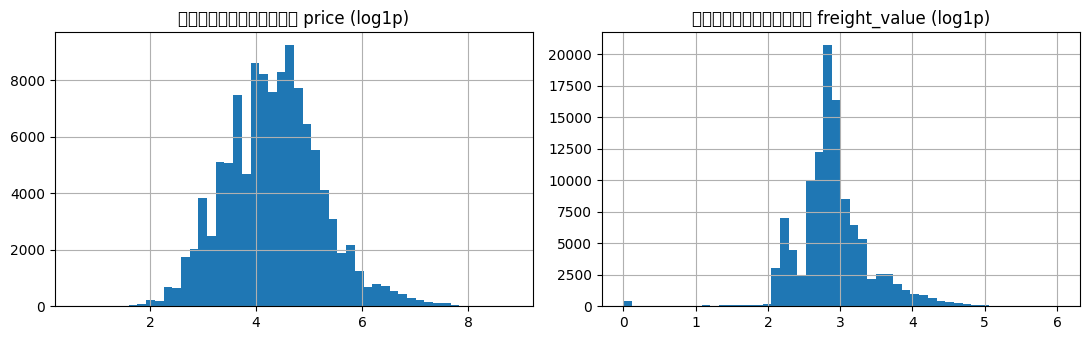

In [ ]:
def iqr_outliers(s):
    q1, q3 = s.quantile([0.25, 0.75])
    upper = q3 + 1.5 * (q3 - q1)
    return int((s > upper).sum()), upper

for col in ["price", "freight_value"]:
    n, upper = iqr_outliers(order_items[col])
    print(f"{col}: เกินเกณฑ์ IQR {n:,} รายการ ({n/len(order_items)*100:.1f}%) | เกณฑ์บน = {upper:,.2f}")

# ดูการกระจายด้วยสเกล log เพราะราคามักเบ้ขวามาก
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
np.log1p(order_items["price"]).hist(bins=50, ax=axes[0])
axes[0].set_title("Distribution of price (log1p)")
np.log1p(order_items["freight_value"]).hist(bins=50, ax=axes[1])
axes[1].set_title("Distribution of freight_value (log1p)")
plt.tight_layout()
plt.show()

In [ ]:
# ตรวจตาราง payments
print("วิธีชำระ:")
display(payments["payment_type"].value_counts().to_frame("รายการ"))
print("payment_value = 0   :", int((payments["payment_value"] == 0).sum()))
print("payment_installments = 0:", int((payments["payment_installments"] == 0).sum()))

วิธีชำระ:


,รายการ
payment_type,
credit_card,76795
boleto,19784
voucher,5775
debit_card,1529
not_defined,3


payment_value = 0   : 9
payment_installments = 0: 2


## 12) สร้างตารางสะอาดระดับออเดอร์ (Order-level Master Table)


In [ ]:
# 1) เก็บเฉพาะออเดอร์ที่ส่งสำเร็จและมีวันที่ลูกค้าได้รับ
d = orders[(orders["order_status"] == "delivered")
           & orders["order_delivered_customer_date"].notna()].copy()
n_before = len(d)

# 2) กันแถวที่ลำดับวันที่ผิดปกติ
bad_order = (
    (d["order_approved_at"] < d["order_purchase_timestamp"])
    | (d["order_delivered_carrier_date"] < d["order_approved_at"])
    | (d["order_delivered_customer_date"] < d["order_delivered_carrier_date"])
)
d = d[~bad_order].copy()
print(f"ออเดอร์ delivered: {n_before:,} -> หลังกันลำดับวันผิด: {len(d):,} (ตัดออก {n_before - len(d):,})")

# เดือนที่สั่งซื้อ (ใช้รวมยอดขายรายเดือน)
d["order_month"] = d["order_purchase_timestamp"].dt.to_period("M").dt.to_timestamp()

ออเดอร์ delivered: 96,470 -> หลังกันลำดับวันผิด: 95,097 (ตัดออก 1,373)


In [ ]:
# 3) สรุป order_items เป็นระดับออเดอร์
items_agg = (order_items.groupby("order_id")
             .agg(items_count=("order_item_id", "count"),
                  revenue=("price", "sum"),
                  freight=("freight_value", "sum"))
             .reset_index())

# 4) JOIN ลูกค้า
cust_cols = ["customer_id", "customer_unique_id", "customer_city", "customer_state"]

master = (d.merge(customers[cust_cols], on="customer_id", how="left")
            .merge(items_agg, on="order_id", how="left"))

# ตรวจความถูกต้องหลัง JOIN: ต้องยังเป็น 1 แถวต่อ 1 ออเดอร์
assert master["order_id"].is_unique, "แถวบวมหลัง JOIN! ตรวจ key ซ้ำอีกครั้ง"
print("master:", master.shape, "| แถวต่อออเดอร์ไม่ซ้ำ OK")

master: (95097, 15) | แถวต่อออเดอร์ไม่ซ้ำ OK


In [ ]:
# ตรวจค่าว่างหลังรวมตาราง
display(missing_report(master))

,missing,missing_%
order_approved_at,14,0.01
order_delivered_carrier_date,1,0.00


## 13) ตอบคำถามธุรกิจ



In [ ]:
print("ออเดอร์ที่ส่งสำเร็จ     :", f"{len(master):,}")
print("ยอดขายรวม (ไม่รวมค่าส่ง):", f"{master['revenue'].sum():,.0f}")
print("ออเดอร์ที่ไม่มีรายการสินค้า:", int(master["revenue"].isna().sum()))

ออเดอร์ที่ส่งสำเร็จ     : 95,097
ยอดขายรวม (ไม่รวมค่าส่ง): 13,045,052
ออเดอร์ที่ไม่มีรายการสินค้า: 0


## 13.1) ยอดขาย: โตหรือชะลอ และรายได้กระจุกตัวแค่ไหน

วิเคราะห์เทรนด์เฉพาะ *เดือนที่ข้อมูลครบ* เพราะช่วงเริ่มกิจการมีออเดอร์น้อยมากและเดือนสุดท้ายของข้อมูลไม่เต็มเดือน ถ้าเอามารวมจะทำให้กราฟดูโตหรือตกผิดปกติ เราจึงตัดเดือนที่มีออเดอร์น้อยกว่า `MIN_MONTH_ORDERS` และเดือนสุดท้ายออก แล้ว **พิมพ์รายชื่อเดือนที่ตัดให้เห็นทุกครั้ง** เพื่อให้ตรวจสอบได้

ยอดขาย (revenue) ตามนิยามคือผลรวมของ `price` ไม่รวมค่าส่ง และนับเฉพาะออเดอร์ที่ส่งสำเร็จ

เดือนที่ตัดออก (ข้อมูลไม่ครบ): ['2016-09', '2016-10', '2016-12', '2018-08']
เดือนที่ใช้วิเคราะห์: 2017-01 ถึง 2018-07 (19 เดือน)


,orders,revenue,mom_%
order_month,,,
2017-12-01,5508,"725,558.51",-26.52
2018-01-01,7045,"922,192.60",27.10
2018-02-01,6543,"824,207.87",-10.63
2018-03-01,7001,"953,311.25",15.66
2018-04-01,6409,"923,081.83",-3.17
2018-05-01,6681,"966,547.76",4.71
2018-06-01,5973,"839,670.34",-13.13
2018-07-01,5593,"796,706.39",-5.12


ยอดขาย 2018 (เดือน [1, 2, 3, 4, 5, 6, 7]) เทียบช่วงเดียวกันของปี 2017: +156.1%
MoM เฉลี่ย 6 เดือนล่าสุด: -1.9% | 6 เดือนก่อนหน้านั้น: +14.2%


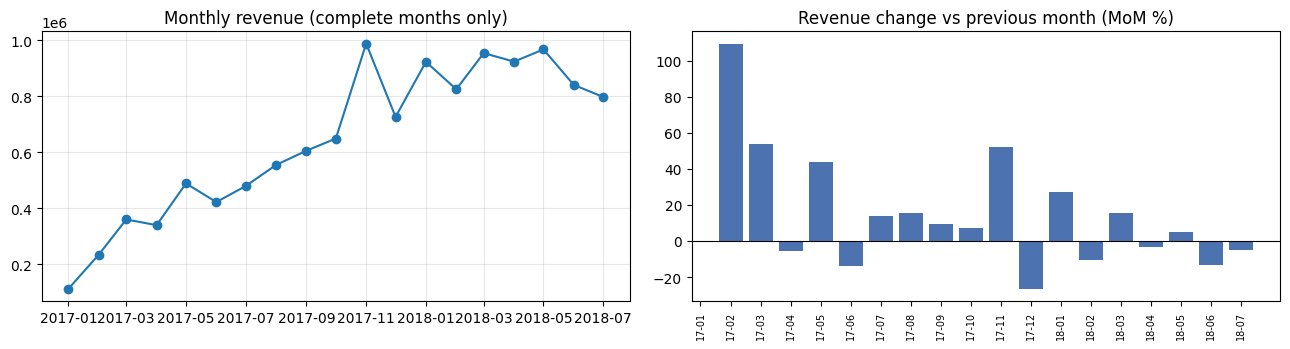

In [ ]:
# ---------- 13.1 ยอดขายรายเดือน (เฉพาะเดือนที่ข้อมูลครบ) ----------
MIN_MONTH_ORDERS = 500   # เดือนที่มีออเดอร์น้อยกว่านี้ถือว่าเป็นช่วงเริ่มต้น/ข้อมูลไม่ครบ 

monthly_all = (master.groupby("order_month")
               .agg(orders=("order_id", "count"), revenue=("revenue", "sum"))
               .sort_index())

last_month = monthly_all.index.max()
excluded = monthly_all[(monthly_all["orders"] < MIN_MONTH_ORDERS) | (monthly_all.index == last_month)]
monthly = monthly_all.drop(index=excluded.index)
print("เดือนที่ตัดออก (ข้อมูลไม่ครบ):", [m.strftime("%Y-%m") for m in excluded.index])
print(f"เดือนที่ใช้วิเคราะห์: {monthly.index.min():%Y-%m} ถึง {monthly.index.max():%Y-%m} ({len(monthly)} เดือน)")

monthly["mom_%"] = monthly["revenue"].pct_change() * 100
display(monthly.tail(8))

# เทียบช่วงเดียวกันของปีก่อน (YoY): ใช้เฉพาะเดือนที่มีครบทั้งสองปี
rev = monthly["revenue"]
latest_year = int(rev.index.year.max())
cur = rev[rev.index.year == latest_year]
prev = rev[(rev.index.year == latest_year - 1) & (rev.index.month.isin(cur.index.month))]
if len(cur) > 0 and len(prev) == len(cur):
    yoy_pct = (cur.sum() / prev.sum() - 1) * 100
    print(f"ยอดขาย {latest_year} (เดือน {sorted(cur.index.month.tolist())}) เทียบช่วงเดียวกันของปี {latest_year - 1}: {yoy_pct:+.1f}%")
else:
    yoy_pct = np.nan
    print("เทียบ YoY ไม่ได้ เพราะเดือนไม่ครบทั้งสองปี")

# การเติบโตชะลอลงหรือไม่: ค่าเฉลี่ย MoM 6 เดือนล่าสุด เทียบ 6 เดือนก่อนหน้า
mom = monthly["mom_%"].dropna()
mom_recent = mom.tail(6).mean() if len(mom) >= 6 else np.nan
mom_prior = mom.iloc[-12:-6].mean() if len(mom) >= 12 else np.nan
print(f"MoM เฉลี่ย 6 เดือนล่าสุด: {mom_recent:+.1f}% | 6 เดือนก่อนหน้านั้น: {mom_prior:+.1f}%")

fig, axes = plt.subplots(1, 2, figsize=(13, 3.6))
axes[0].plot(monthly.index, monthly["revenue"], marker="o")
axes[0].set_title("Monthly revenue (complete months only)"); axes[0].grid(alpha=0.3)
axes[1].bar(range(len(monthly)), monthly["mom_%"], color="#4C72B0")
axes[1].axhline(0, color="black", lw=0.8)
axes[1].set_title("Revenue change vs previous month (MoM %)")
axes[1].set_xticks(range(len(monthly)))
axes[1].set_xticklabels([t.strftime("%y-%m") for t in monthly.index], rotation=90, fontsize=7)
plt.tight_layout(); plt.show()

จำนวนหมวดทั้งหมด: 74 | ต้องใช้ 18 หมวด (24% ของหมวด) จึงครอบคลุม 80% ของยอดขาย
Top 5 หมวด = 39.8% | Top 10 หมวด = 62.4% ของยอดขาย


,revenue,share_%,cum_share_%
category_en,,,
health_beauty,"1,211,552.01",9.29,9.29
watches_gifts,"1,151,417.87",8.83,18.11
bed_bath_table,"1,008,243.08",7.73,25.84
sports_leisure,"944,118.98",7.24,33.08
computers_accessories,"877,235.31",6.72,39.80
furniture_decor,"703,283.55",5.39,45.20
cool_stuff,"605,603.15",4.64,49.84
housewares,"603,595.53",4.63,54.47
auto,"573,107.67",4.39,58.86


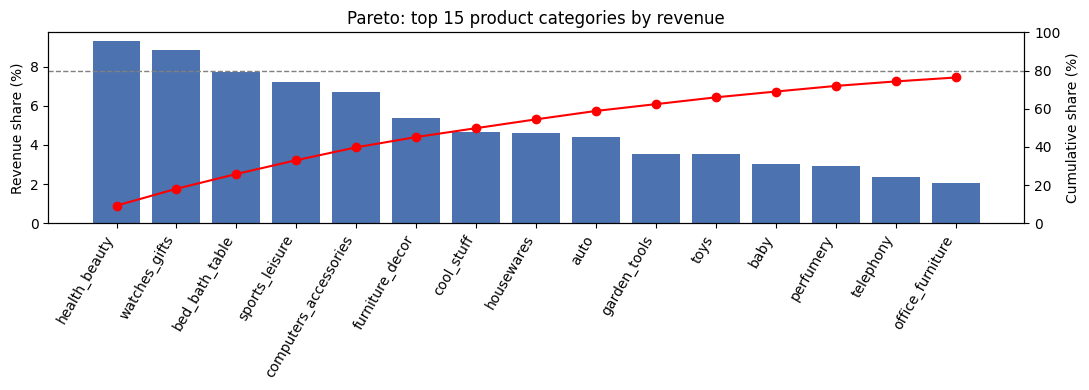

In [ ]:
# ---------- 13.1 (ต่อ) รายได้กระจุกตัวแค่ไหน: Pareto ตามหมวดสินค้า ----------
items_ok = order_items[order_items["order_id"].isin(master["order_id"])]
cat_rev = (items_ok.merge(products.drop_duplicates("product_id")[["product_id", "category_en"]],
                          on="product_id", how="left")
           .assign(category_en=lambda x: x["category_en"].fillna("unknown"))
           .groupby("category_en")["price"].sum()
           .sort_values(ascending=False))

# ตรวจความสอดคล้อง: ยอดรวมรายหมวดต้องเท่ากับยอดขายรวมในตาราง master
assert np.isclose(cat_rev.sum(), master["revenue"].sum()), "ยอดรวมรายหมวดไม่ตรงกับ master ตรวจการ JOIN"

pareto = pd.DataFrame({"revenue": cat_rev,
                       "share_%": cat_rev / cat_rev.sum() * 100,
                       "cum_share_%": cat_rev.cumsum() / cat_rev.sum() * 100})
n_cat = len(pareto)
n_cat_80 = int((pareto["cum_share_%"] < 80).sum() + 1)       # จำนวนหมวดที่รวมกันถึง 80% ของยอดขาย
top5_share = pareto["share_%"].head(5).sum()
top10_share = pareto["share_%"].head(10).sum()
print(f"จำนวนหมวดทั้งหมด: {n_cat} | ต้องใช้ {n_cat_80} หมวด ({n_cat_80 / n_cat * 100:.0f}% ของหมวด) จึงครอบคลุม 80% ของยอดขาย")
print(f"Top 5 หมวด = {top5_share:.1f}% | Top 10 หมวด = {top10_share:.1f}% ของยอดขาย")
display(pareto.head(10))

top = pareto.head(15)
fig, ax = plt.subplots(figsize=(11, 4))
ax.bar(range(len(top)), top["share_%"], color="#4C72B0")
ax.set_xticks(range(len(top))); ax.set_xticklabels(top.index, rotation=60, ha="right")
ax.set_ylabel("Revenue share (%)")
ax2 = ax.twinx(); ax2.plot(range(len(top)), top["cum_share_%"], color="red", marker="o")
ax2.set_ylim(0, 100); ax2.set_ylabel("Cumulative share (%)"); ax2.axhline(80, ls="--", color="gray", lw=1)
ax.set_title("Pareto: top 15 product categories by revenue")
plt.tight_layout(); plt.show()

## 13.2) รวมตัวเลขสำคัญไว้ที่เดียว (สำหรับ README / Resume)

เซลล์ด้านล่างรวมตัวเลขจากทั้งโน้ตบุ๊กและบันทึกเป็น `output/key_numbers.csv` เพื่อคัดลอกไปใช้ได้ถูกต้องและไม่ต้องไล่หาในหลายเซลล์ **ใช้ตัวเลขจากการรันรอบเดียวกันเท่านั้น**

In [ ]:
# ---------- 13.2 สรุปตัวเลขสำคัญ ----------
n_orders_before = n_before                       # จากหัวข้อ 12: delivered และมีวันที่ลูกค้าได้รับ
n_orders_after = len(master)
key_numbers = pd.DataFrame([
    ("ข้อมูลดิบ", "จำนวนตาราง", len(dfs)),
    ("ข้อมูลดิบ", "จำนวนแถวรวมทุกตาราง", sum(len(tbl) for tbl in dfs.values())),
    ("คุณภาพข้อมูล", "ออเดอร์ delivered (ก่อนกันลำดับวันผิด)", n_orders_before),
    ("คุณภาพข้อมูล", "ออเดอร์ในตารางสะอาด (master)", n_orders_after),
    ("คุณภาพข้อมูล", "แถวที่ตัดออก (ลำดับวันที่ผิด)", n_orders_before - n_orders_after),
    ("ยอดขาย", "YoY ช่วงเดียวกันของปีก่อน (%)", yoy_pct),
    ("ยอดขาย", "MoM เฉลี่ย 6 เดือนล่าสุด (%)", mom_recent),
    ("ยอดขาย", "MoM เฉลี่ย 6 เดือนก่อนหน้านั้น (%)", mom_prior),
    ("ยอดขาย", "จำนวนหมวดที่ครอบคลุม 80% ของยอดขาย", n_cat_80),
    ("ยอดขาย", "สัดส่วนยอดขาย Top 5 หมวด (%)", top5_share),
], columns=["หมวด", "ตัวเลข", "ค่า"])

Path("output").mkdir(exist_ok=True)
key_numbers.to_csv("output/key_numbers.csv", index=False)
display(key_numbers.style.format({"ค่า": "{:,.2f}"}))

,หมวด,ตัวเลข,ค่า
0,ข้อมูลดิบ,จำนวนตาราง,8.00
1,ข้อมูลดิบ,จำนวนแถวรวมทุกตาราง,"1,451,698.00"
2,คุณภาพข้อมูล,ออเดอร์ delivered (ก่อนกันลำดับวันผิด),"96,470.00"
3,คุณภาพข้อมูล,ออเดอร์ในตารางสะอาด (master),"95,097.00"
4,คุณภาพข้อมูล,แถวที่ตัดออก (ลำดับวันที่ผิด),"1,373.00"
5,ยอดขาย,YoY ช่วงเดียวกันของปีก่อน (%),156.10
6,ยอดขาย,MoM เฉลี่ย 6 เดือนล่าสุด (%),-1.94
7,ยอดขาย,MoM เฉลี่ย 6 เดือนก่อนหน้านั้น (%),14.17
8,ยอดขาย,จำนวนหมวดที่ครอบคลุม 80% ของยอดขาย,18.00
9,ยอดขาย,สัดส่วนยอดขาย Top 5 หมวด (%),39.80


## 14) บันทึกตารางสะอาด

In [ ]:
OUT_DIR = Path("output")
OUT_DIR.mkdir(exist_ok=True)

master.to_csv(OUT_DIR / "olist_orders_clean.csv", index=False)

# ตารางหมวดสินค้าที่แปลชื่อแล้ว ใช้ทำ dimension ใน Power BI
products[["product_id", "category_en"]].to_csv(OUT_DIR / "dim_products_clean.csv", index=False)
print("บันทึกแล้วที่", OUT_DIR.resolve())

บันทึกแล้วที่ /content/output


In [ ]:
import shutil
from google.colab import files

# คัดลอก CSV ต้นฉบับ 9 ไฟล์มารวมกับไฟล์ที่ทำความสะอาดแล้ว
shutil.copytree(DATA_DIR, "output/raw", dirs_exist_ok=True)

shutil.make_archive("olist_files", "zip", "output")
files.download("olist_files.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>